# 02. Model evaluation
Compare three models on the same stratified split, with a focus on the churn class.

In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

from src.metrics import evaluate
from src.preprocess import make_preprocessor
from src.split import load_split

X_train, X_test, y_train, y_test = load_split()

## Train three models and compare test metrics

In [2]:
models = {
    "LogReg": make_pipeline(make_preprocessor(), LogisticRegression(max_iter=1000)),
    "LogReg balanced": make_pipeline(make_preprocessor(), LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Random Forest balanced": make_pipeline(make_preprocessor(), RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced", n_jobs=-1, random_state=42)),
}
for m in models.values():
    m.fit(X_train, y_train)

results = pd.DataFrame({n: evaluate(m, X_test, y_test) for n, m in models.items()}).T
results.round(3)

,accuracy,precision,recall,f1,roc_auc
LogReg,0.806,0.657,0.559,0.604,0.842
LogReg balanced,0.738,0.504,0.783,0.614,0.842
Random Forest balanced,0.763,0.537,0.781,0.636,0.840


## Cross-validation (5-fold, F1 on the churn class)

In [3]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

skf = StratifiedKFold(5, shuffle=True, random_state=42)
cv = {n: cross_val_score(m, X_train, y_train, cv=skf, scoring="f1", n_jobs=-1) for n, m in models.items()}
pd.DataFrame(cv).agg(["mean", "std"]).round(3)

,LogReg,LogReg balanced,Random Forest balanced
mean,0.592,0.628,0.632
std,0.033,0.026,0.017


## Confusion matrices

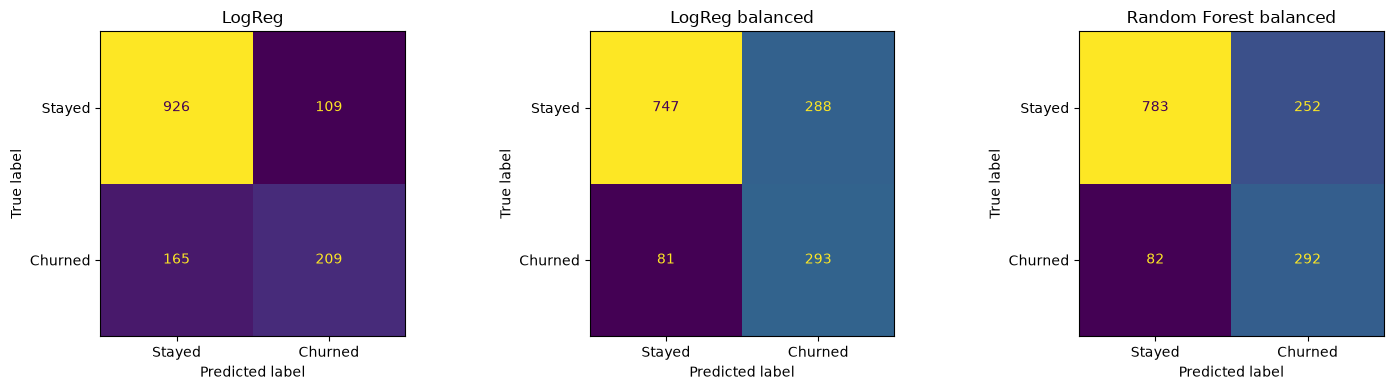

In [4]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (n, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, display_labels=["Stayed", "Churned"], ax=ax, colorbar=False)
    ax.set_title(n)
plt.tight_layout()
plt.show()

## Precision-recall curves

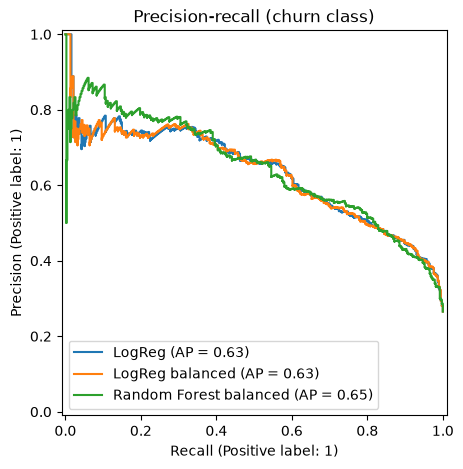

In [5]:
from sklearn.metrics import PrecisionRecallDisplay

fig, ax = plt.subplots(figsize=(6, 5))
for n, m in models.items():
    PrecisionRecallDisplay.from_estimator(m, X_test, y_test, name=n, ax=ax)
ax.set_title("Precision-recall (churn class)")
plt.show()